## Stroke Prediction Dataset

Part 1: Data Loading & Initial Inspection

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

sns.set_style("whitegrid")

In [64]:
!pip install kagglehub

In [65]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "healthcare-dataset-stroke-data.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "fedesoriano/stroke-prediction-dataset",
    file_path
)

df.head()

/tmp/ipykernel_1984/1725591518.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [67]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [68]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [69]:
df.shape

(5110, 12)

Part 2: Exploratory Data Analysis & Visualization



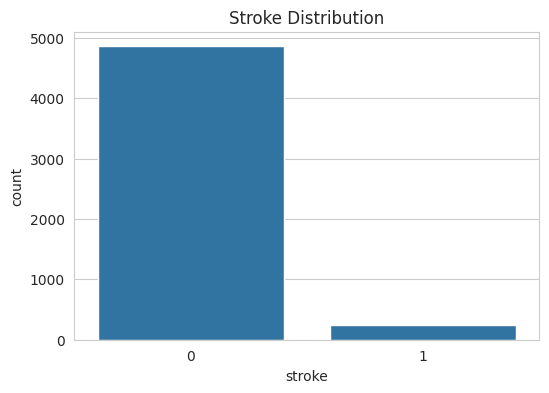

In [70]:
plt.figure(figsize=(6,4))
sns.countplot(data = df , x = 'stroke')
plt.title('Stroke Distribution')
plt.xlabel('stroke')
plt.ylabel('count')
plt.show()

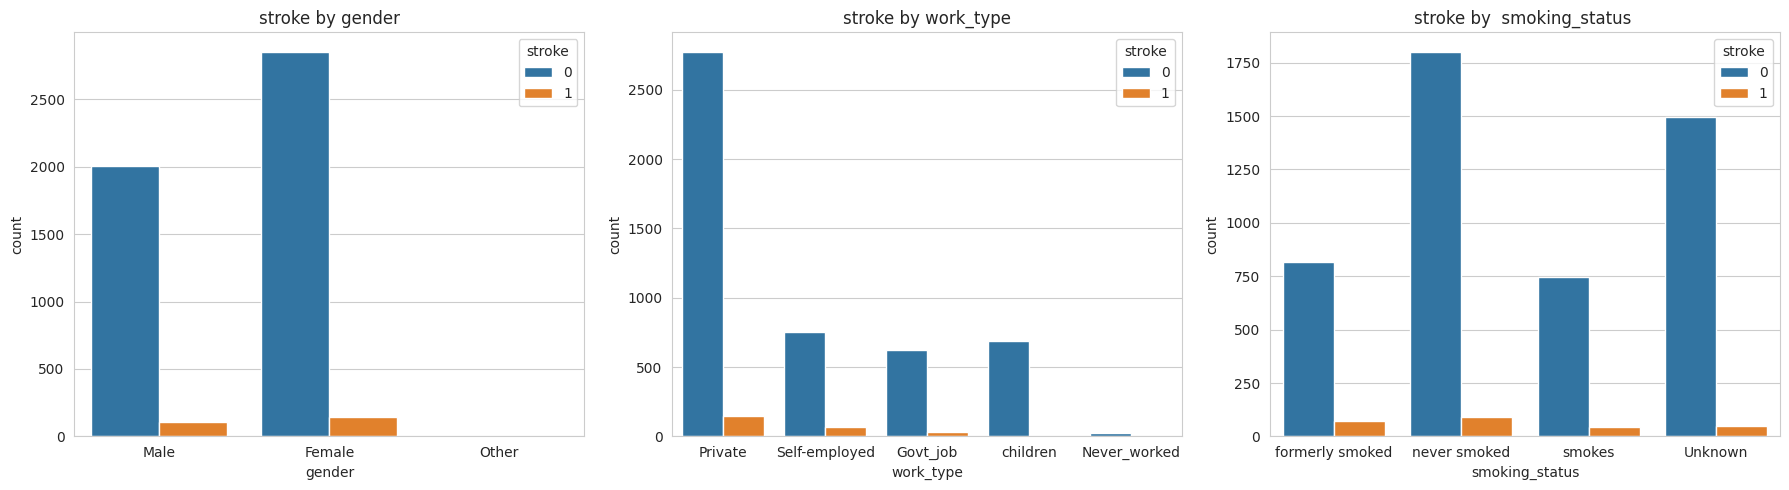

In [71]:
fig , axes = plt.subplots(1,3 , figsize=(18,5))

#gender
sns.countplot(data=df , x='gender' , hue = 'stroke' , ax=axes[0])
axes[0].set_title('stroke by gender')
axes[0].set_xlabel('gender')
axes[0].set_ylabel('count')

# work_type
sns.countplot(data=df , x='work_type' , hue = 'stroke' , ax=axes[1])
axes[1].set_title('stroke by work_type')
axes[1].set_xlabel('work_type')
axes[1].set_ylabel('count')

#  smoking_status
sns.countplot(data=df , x ='smoking_status' , hue = 'stroke' , ax=axes[2])
axes[2].set_title('stroke by  smoking_status ')
axes[2].set_xlabel('smoking_status')
axes[2].set_ylabel('count')

plt.tight_layout()
plt.show()

In [72]:
df['gender'].value_counts()

,count
gender,
Female,2994
Male,2115
Other,1


In [73]:
df = df[df["gender"] != "Other"].reset_index(drop=True)

In [74]:
df['gender'].value_counts()

,count
gender,
Female,2994
Male,2115


In [75]:
df.shape

(5109, 12)

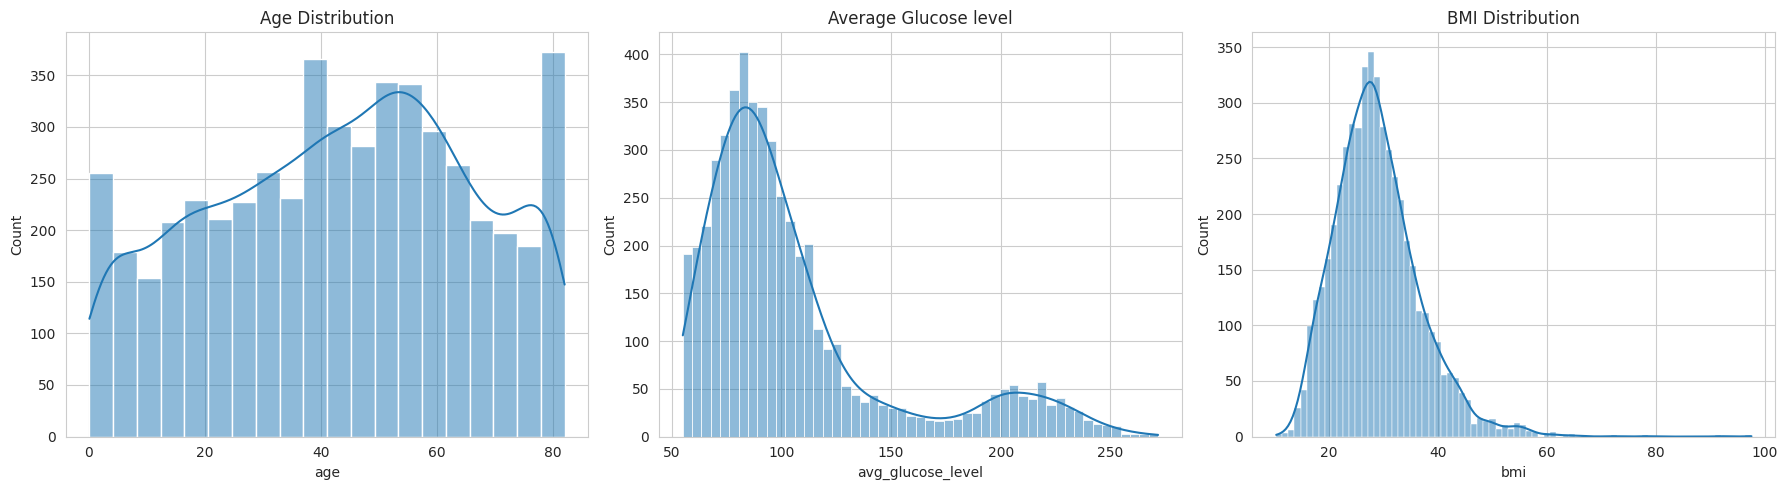

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age
sns.histplot(data=df, x='age', kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')

# Average Glucose level
sns.histplot(data=df, x='avg_glucose_level', kde=True, ax=axes[1])
axes[1].set_title('Average Glucose level')

# BMI
sns.histplot(data=df, x='bmi', kde=True, ax=axes[2])
axes[2].set_title('BMI Distribution')

plt.tight_layout()
plt.show()

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5109 entries, 0 to 5108
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5109 non-null   int64  
 1   gender             5109 non-null   object 
 2   age                5109 non-null   float64
 3   hypertension       5109 non-null   int64  
 4   heart_disease      5109 non-null   int64  
 5   ever_married       5109 non-null   object 
 6   work_type          5109 non-null   object 
 7   Residence_type     5109 non-null   object 
 8   avg_glucose_level  5109 non-null   float64
 9   bmi                4908 non-null   float64
 10  smoking_status     5109 non-null   object 
 11  stroke             5109 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.1+ KB


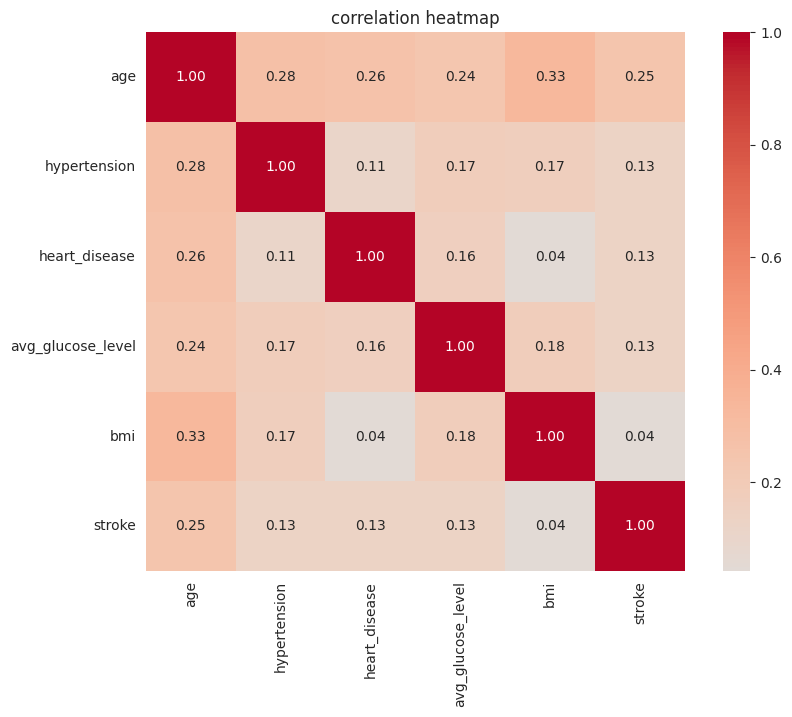

In [78]:
# Select numerical features
numerical_features = [
    'age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']

# Calculate correlation
corr = df[numerical_features].corr()

# heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)

plt.title('correlation heatmap')
plt.show()

## Part 3: Data Preprocessing (Cleaning)

In [79]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [80]:
df['bmi']= df['bmi'].fillna(df['bmi'].median())

In [81]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


In [82]:
df.duplicated().sum()

np.int64(0)

In [83]:
df = df.drop('id', axis=1)

In [84]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

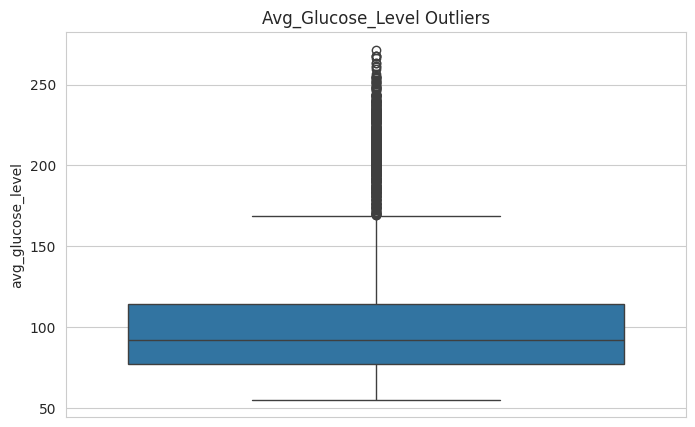

In [85]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y='avg_glucose_level')
plt.title('Avg_Glucose_Level Outliers')
plt.show()

In [86]:
Q1 = df['avg_glucose_level'].quantile(0.25)
Q3 = df['avg_glucose_level'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print('Lower Bound :', lower_bound )
print('Upper Bound : ', upper_bound)

Lower Bound : 21.964999999999982
Upper Bound :  169.365


In [87]:
outliers = df[
    (df['avg_glucose_level'] < lower_bound) |
    (df['avg_glucose_level'] > upper_bound)
]

print("Number of Outliers:", len(outliers))

Number of Outliers: 627


In [88]:
low_outliers = df[df['avg_glucose_level'] < lower_bound]

high_outliers = df[df['avg_glucose_level'] > upper_bound]

print("Low Outliers:", len(low_outliers))
print("High Outliers:", len(high_outliers))

Low Outliers: 0
High Outliers: 627


In [89]:
high_outliers['avg_glucose_level'].describe()

,avg_glucose_level
count,627.000000
mean,211.341595
std,20.825706
min,169.430000
25%,196.760000
50%,210.000000
75%,226.715000
max,271.740000


Outliers were kept because they may represent real medical conditions and contain useful information for stroke prediction.

## Part 4: Feature Transformation

In [90]:
categorical_columns = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status']

df[categorical_columns].head()

,gender,ever_married,work_type,Residence_type,smoking_status
0,Male,Yes,Private,Urban,formerly smoked
1,Female,Yes,Self-employed,Rural,never smoked
2,Male,Yes,Private,Rural,never smoked
3,Female,Yes,Private,Urban,smokes
4,Female,Yes,Self-employed,Rural,never smoked


In [91]:
# Binary Encoding
df['gender'] = df['gender'].map({'Male':0, 'Female':1})
df['ever_married'] = df['ever_married'].map({'No':0, 'Yes':1})
df['Residence_type'] = df['Residence_type'].map({'Rural':0, 'Urban':1})

# One Hot Encoding
df = pd.get_dummies(
    df,
    columns=['work_type', 'smoking_status'],
    drop_first=True,
    dtype=int
)
df.head()

,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,0,67.0,0,1,1,1,228.69,36.6,1,0,1,0,0,1,0,0
1,1,61.0,0,0,1,0,202.21,28.1,1,0,0,1,0,0,1,0
2,0,80.0,0,1,1,0,105.92,32.5,1,0,1,0,0,0,1,0
3,1,49.0,0,0,1,1,171.23,34.4,1,0,1,0,0,0,0,1
4,1,79.0,1,0,1,0,174.12,24.0,1,0,0,1,0,0,1,0


In [92]:
print(df.columns.tolist())
print(df.iloc[0])

['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'avg_glucose_level', 'bmi', 'stroke', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']
gender                              0.00
age                                67.00
hypertension                        0.00
heart_disease                       1.00
ever_married                        1.00
Residence_type                      1.00
avg_glucose_level                 228.69
bmi                                36.60
stroke                              1.00
work_type_Never_worked              0.00
work_type_Private                   1.00
work_type_Self-employed             0.00
work_type_children                  0.00
smoking_status_formerly smoked      1.00
smoking_status_never smoked         0.00
smoking_status_smokes               0.00
Name: 0, dtype: float64


In [93]:
df.index

RangeIndex(start=0, stop=5109, step=1)

## Part 5: Data Splitting

In [94]:
x = df.drop('stroke', axis=1)
y = df['stroke']

In [95]:
print("X shape:", x.shape)
print("y shape:", y.shape)

X shape: (5109, 15)
y shape: (5109,)


In [96]:
x_train, x_test, y_train, y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=42
)

In [97]:
print('X_train', x_train.shape)
print('X_test', x_test.shape)
print('Y_train', y_train.shape)
print('Y_test', y_test.shape)

X_train (4087, 15)
X_test (1022, 15)
Y_train (4087,)
Y_test (1022,)


## Part 6: Feature Scaling

In [98]:
scaler = StandardScaler()
scale_columns = ['age', 'avg_glucose_level', 'bmi']
x_train[scale_columns] = scaler.fit_transform(x_train[scale_columns])
x_test[scale_columns] = scaler.transform(x_test[scale_columns])

In [99]:
x_train[scale_columns].describe()

,age,avg_glucose_level,bmi
count,4.087000e+03,4.087000e+03,4.087000e+03
mean,2.781670e-17,1.747236e-16,-1.636404e-16
std,1.000122e+00,1.000122e+00,1.000122e+00
min,-1.901125e+00,-1.123641e+00,-2.396548e+00
25%,-7.992014e-01,-6.402855e-01,-6.551662e-01
50%,4.094884e-02,-3.180855e-01,-1.005039e-01
75%,7.926622e-01,1.753967e-01,5.057548e-01
max,1.721249e+00,3.645403e+00,8.864385e+00


## Part 7: Handling Class Imbalance

In [100]:
print(y_train.value_counts())

stroke
0    3900
1     187
Name: count, dtype: int64


In [101]:
ros = RandomOverSampler(random_state=42)
x_train, y_train = ros.fit_resample(x_train, y_train)

In [102]:
print(y_train.value_counts())

stroke
0    3900
1    3900
Name: count, dtype: int64


## Conclusion


### High-Risk Stroke Patient Persona

A 67-year-old married individual with hypertension and heart disease, a high average glucose level (228.69), and a BMI of 36.6. This individual represents a potentially high-risk profile based on several factors associated with stroke in the dataset.

These factors may increase the likelihood of stroke, but they do not guarantee that a person will experience one.

### Summary of Findings

- The dataset initially contained 5,110 records and 12 columns.
- The target variable, `stroke`, was highly imbalanced, with approximately 95% of cases having no stroke and 5% having stroke.
- Missing BMI values were handled using median imputation.
- Duplicate records were checked, the ID column was removed, and potential glucose-level outliers were retained because they may represent meaningful medical information.
- Categorical features were encoded using binary encoding and one-hot encoding.
- The dataset was split into 80% training and 20% testing data using `random_state=42`.
- Numerical features (`age`, `avg_glucose_level`, and `bmi`) were scaled using StandardScaler.
- RandomOverSampler was applied to the training data to balance the two classes, while the test data remained unchanged.

